In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout
)

from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

In [ ]:
# Step 2: Load Dataset

In [2]:
train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")

print("Training Dataset:", train_data.shape)
print("Testing Dataset:", test_data.shape)

Training Dataset: (27455, 785)
Testing Dataset: (7172, 785)


In [3]:
X_train = train_data.iloc[:, 1:].values
y_train = train_data.iloc[:, 0].values

X_test = test_data.iloc[:, 1:].values
y_test = test_data.iloc[:, 0].values

In [ ]:
# Normalize Pixel Values

In [4]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [ ]:
# Reshape Images ,Encode Labels

In [5]:
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

classes = np.unique(np.concatenate((y_train, y_test)))

label_mapping = {
    label: index for index, label in enumerate(classes)
}

y_train = np.array([label_mapping[label] for label in y_train])
y_test = np.array([label_mapping[label] for label in y_test])

num_classes = len(classes)

print("Number of Classes:", num_classes)
print("Training Shape:", X_train.shape)

Number of Classes: 24
Training Shape: (27455, 28, 28, 1)


#### CHIT 6: Basic CNN + Testing Accuracy

In [ ]:
# Create CNN Model

In [6]:
model = Sequential([

    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation='relu'),

    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),

    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),

    Dropout(0.3),

    Dense(num_classes, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 24)                  │           3,096 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 226,840 (886.09 KB)

 Trainable params: 226,840 (886.09 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile Model

In [7]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
# Train Model

In [8]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 21s 77ms/step - accuracy: 0.4111 - loss: 1.9578 - val_accuracy: 0.8128 - val_loss: 0.7340
Epoch 2/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 14s 71ms/step - accuracy: 0.7901 - loss: 0.6486 - val_accuracy: 0.9323 - val_loss: 0.2603
Epoch 3/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 14s 71ms/step - accuracy: 0.8993 - loss: 0.3167 - val_accuracy: 0.9894 - val_loss: 0.0941
Epoch 4/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 14s 72ms/step - accuracy: 0.9443 - loss: 0.1811 - val_accuracy: 0.9927 - val_loss: 0.0489
Epoch 5/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 14s 74ms/step - accuracy: 0.9660 - loss: 0.1146 - val_accuracy: 0.9996 - val_loss: 0.0160
Epoch 6/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 14s 70ms/step - accuracy: 0.9766 - loss: 0.0811 - val_accuracy: 0.9996 - val_loss: 0.0139
Epoch 7/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 15s 75ms/step - accuracy: 0.9819 - loss: 0.0635 - val_accuracy: 1.0000 - val_loss: 0.0068
Epoch 8/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 19s 69ms/step - accuracy: 0.9855 - loss: 0.0501 - 

In [ ]:
# Display Training Accuracy

In [9]:
train_loss, train_accuracy = model.evaluate(
    X_train, y_train
)

print("Training Accuracy:", train_accuracy * 100, "%")

858/858 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9999 - loss: 0.0040
Training Accuracy: 99.9854326248169 %


In [ ]:
# Display Testing Accuracy

In [10]:
test_loss, test_accuracy = model.evaluate(
    X_test, y_test
)

print("Testing Accuracy:", test_accuracy * 100, "%")

225/225 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.9133 - loss: 0.3423
Testing Accuracy: 91.32738709449768 %


In [ ]:
# Plot Training and Validation Accuracy Graph

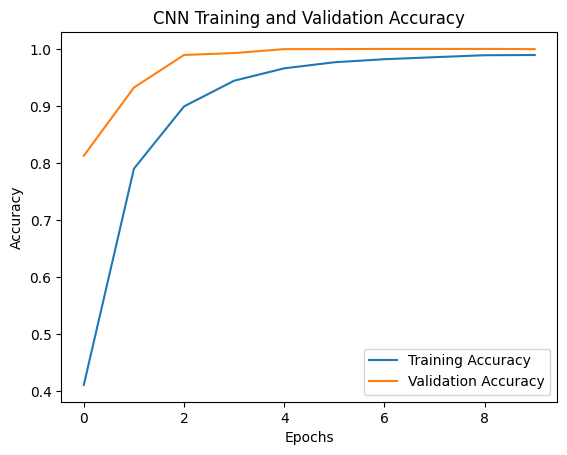

In [11]:
plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('CNN Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.show()

In [ ]:
# Plot Training and Validation Loss Graph

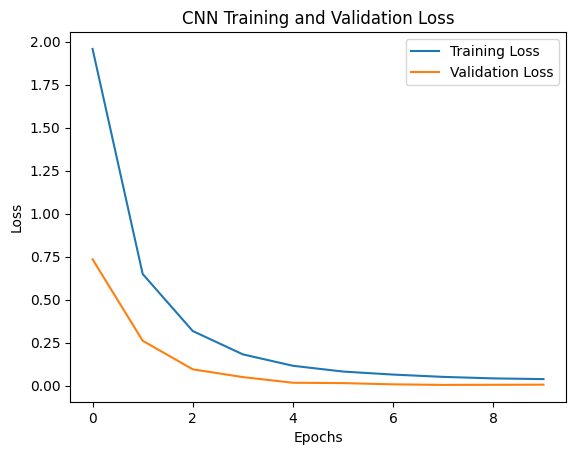

In [12]:
plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('CNN Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.show()

#### CHIT 7: CNN + Five Predicted Alphabet Labels

In [13]:
# Predict Five Test Images

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 399ms/step


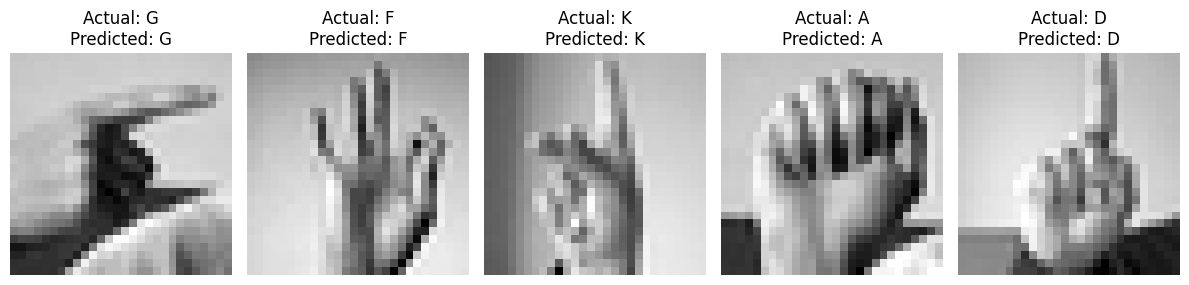

In [14]:
predictions = model.predict(X_test[:5])

predicted_labels = np.argmax(predictions, axis=1)

alphabet = [
    chr(label + 65)
    for label in classes
]

plt.figure(figsize=(12, 5))

for i in range(5):

    plt.subplot(1, 5, i + 1)

    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    actual = alphabet[y_test[i]]
    predicted = alphabet[predicted_labels[i]]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [16]:
# Extract and Visualize CNN Features

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 277ms/step


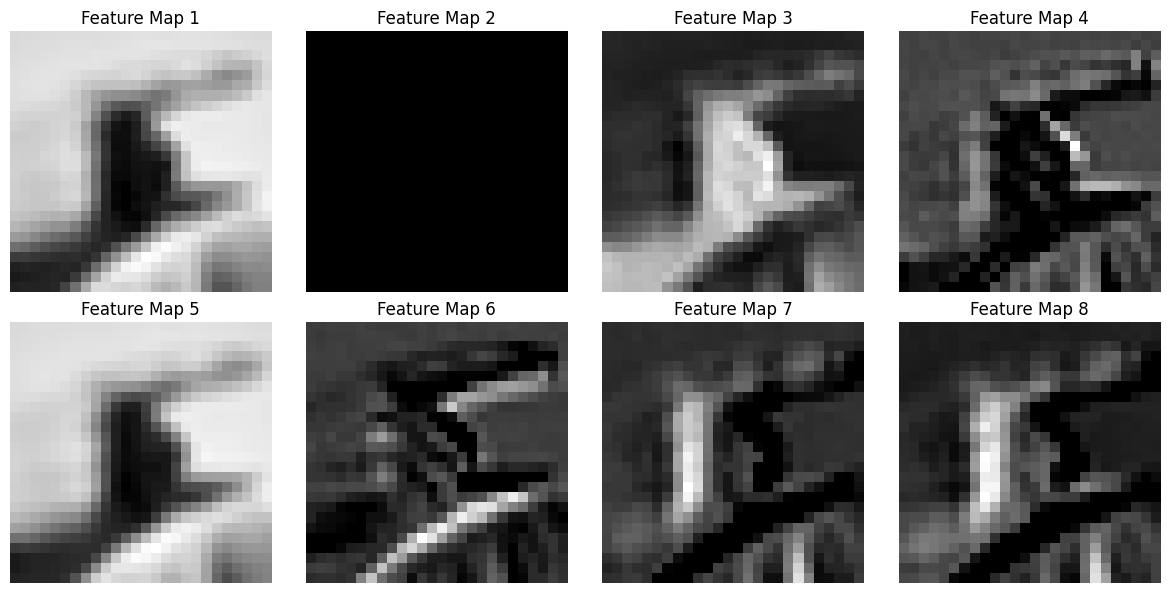

In [19]:
# Create feature extraction model
feature_model = Model(
    inputs=model.inputs,
    outputs=model.layers[0].output
)

# Extract features from one test image
features = feature_model.predict(X_test[:1])

# Display 8 feature maps
plt.figure(figsize=(12, 6))

for i in range(8):

    plt.subplot(2, 4, i + 1)

    plt.imshow(features[0, :, :, i], cmap='gray')

    plt.title(f"Feature Map {i + 1}")

    plt.axis('off')

plt.tight_layout()
plt.show()

CHIT 6: Basic CNN + Testing Accuracy
CHIT 7: CNN + Five Predicted Alphabet Labels 
CHIT 8: CNN + Training Accuracy, Testing Accuracy and Loss Graph
CHIT 9: CNN + Five Actual and Predicted Alphabet Images
CHIT 10: CNN Feature Extraction + Testing Accuracy